<div style = "border: 1px solid black">
<b><center><font size = "6
"> Mini-Projeto </font><center></b>

</font><center></b>
</div>



---



`Nome:` Leonor Rebola <br>
`Número:` 53663 <br>
`Email:` leonor.rebola@ubi.pt <br>

`Nome:` Adriana Abreu <br>
`Número:` 53672 <br>
`Email:` adriana.abreu@ubi.pt <br>

`Curso:` Inteligência Artificial e Ciência de Dados <br>
`UC:` Análise de Dados <br>


---



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('bank-additional-full.csv', sep=';')
df.shape  # esperado: (41188, 21)

(41188, 21)

### **Parte A**

---



a) Para cada um dos 4 conjuntos, calcule média de x, média de y, correlação e a reta de regressão. Apresente numa tabela única (dica: groupby('dataset')).

,media_x,media_y,correlacao,declive,ordenada
dataset,,,,,
I,9.0,7.501,0.816,0.5,3.000
II,9.0,7.501,0.816,0.5,3.001
III,9.0,7.500,0.816,0.5,3.002
IV,9.0,7.501,0.817,0.5,3.002


As 4 tabelas têm estatísticas praticamente idênticas: média de x = 9, média de y ≈ 7,5, correlação ≈ 0,82 e reta y ≈ 3 + 0,5x. Só pelos números, os conjuntos pareceriam iguais.

b) Construa a grelha 2×2 de scatter plots (um por conjunto), com a reta de regressão sobreposta (sns.lmplot com col='dataset').

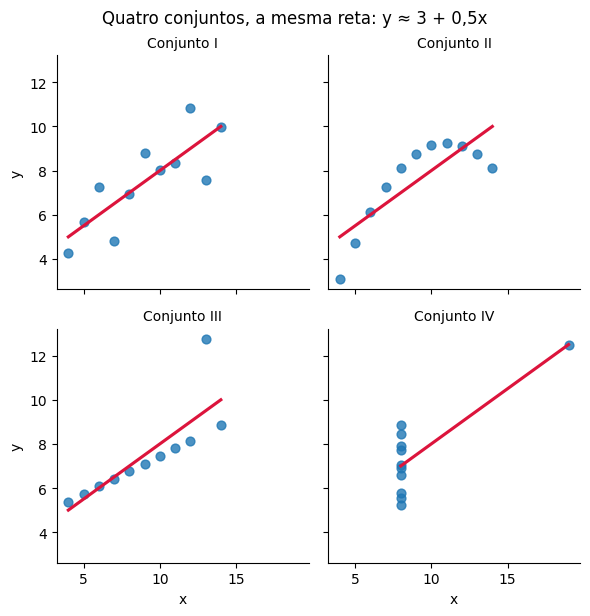

In [ ]:
g = sns.lmplot(data=ans, x='x', y='y', col='dataset', col_wrap=2,
               height=3, ci=None,
               scatter_kws={'s': 40}, line_kws={'color': 'crimson'})
g.set_titles('Conjunto {col_name}')
g.figure.suptitle('Quatro conjuntos, a mesma reta: y ≈ 3 + 0,5x', y=1.02)
plt.show()

Só o conjunto I é uma relação linear com ruído. O II é uma curva (parábola), o III é linear com um outlier que desvia a reta, e o IV tem todos os x iguais menos um ponto de alavanca que sozinho define a reta.

c) Em Markdown (3–4 linhas): que lição prática retira para o seu fluxo de trabalho de análise?

As estatísticas descritivas resumem os dados, mas não os substituem: conjuntos muito diferentes podem dar médias, correlações e retas iguais. Por isso devo visualizar sempre os dados antes de modelar, e não confiar só em números-resumo. O gráfico revela não-linearidade, outliers e pontos de alavanca que os números escondem. No meu fluxo de trabalho, o scatter plot e o histograma vêm antes do describe() e da regressão.

### **Parte B**

---



B1 - Valores duplicados

In [2]:
n_duplicadas = df.duplicated().sum()
print(f"Linhas duplicadas: {n_duplicadas} ({n_duplicadas/len(df):.3%})")

# ver as duplicadas (mantém todas as ocorrências)
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Linhas duplicadas: 12 (0.029%)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape depois de remover duplicados:", df.shape)

Shape depois de remover duplicados: (41176, 21)


Neste dataset, existe 12 linhas duplicadas.

Decidiu-se remover estas linhas devido ao facto de não haver um id de cliente, podendo-se tratar de registos repetidos.

B2 - Valores em falta escondidos

In [19]:
df_raw = pd.read_csv('bank-additional-full.csv', sep=';')
print("isnull total:", df_raw.isnull().sum().sum())   # 0
(df_raw == 'unknown').sum()[lambda s: s > 0]

isnull total: 0


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

In [20]:
df = df.replace('unknown', np.nan)

faltas = pd.DataFrame({
    'n_em_falta': df.isnull().sum(),
    'pct_em_falta': (df.isnull().mean() * 100).round(2)
})
faltas = faltas[faltas.n_em_falta > 0].sort_values('n_em_falta', ascending=False)
faltas

,n_em_falta,pct_em_falta
pdays_dias,39661,96.32
default,8596,20.88
education,1730,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


In [21]:
df['y_bin'] = (df['y'] == 'yes').astype(int)

taxa = (df.groupby(df['default'].isnull())['y_bin']
          .agg(['mean', 'count'])
          .rename(index={True: 'default em falta', False: 'default preenchido'}))
taxa['mean'] = (taxa['mean'] * 100).round(2)
taxa.columns = ['taxa_yes_%', 'n']
taxa

,taxa_yes_%,n
default,,
default preenchido,12.88,32580
default em falta,5.15,8596


In [22]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(df['default'].isnull(), df['y_bin'])
chi2, p, _, _ = chi2_contingency(ct)
print(f"qui-quadrado p-value = {p:.2e}")

qui-quadrado p-value = 3.89e-90


Antes do tratamento, isnull() dá 0 em todas as colunas, mas há “unknown” em 6 variáveis, ou seja, falta escrita como texto. 

Convertidos para NaN, default tem 20,88 % em falta, education 4,20 %, housing e loan 2,40 %, job 0,80 % e marital 0,19 %. Em default, a taxa de yes é 5,15 % quando falta e 12,88 % quando está preenchido (p ≈ 4×10⁻⁹⁰), logo a falta tem informação. 

Decidiu-se tratá-los como categoria própria (“desconhecido”), porque remover perderia 21 % dos dados e imputar a moda apagaria este sinal.

B3 - pdays

In [23]:
df['pdays'].value_counts().head()

pdays
999    39661
3        439
6        412
4        118
9         64
Name: count, dtype: int64

In [24]:
df['pdays'].value_counts().head()
(df['pdays'] == 999).mean()

np.float64(0.9632067223625412)

In [25]:
df['pdays_contactado'] = (df['pdays'] != 999).astype(int)
df['pdays_dias'] = df['pdays'].where(df['pdays'] != 999, np.nan)

# comparação com poutcome
print(pd.crosstab(df['pdays_contactado'], df['poutcome'].fillna('NaN (desconhecido)')))
print()
print(pd.crosstab(df['pdays_contactado'], df['poutcome'].fillna('NaN (desconhecido)'), normalize='index').round(3))

poutcome          failure  nonexistent  success
pdays_contactado                               
0                    4110        35551        0
1                     142            0     1373

poutcome          failure  nonexistent  success
pdays_contactado                               
0                   0.104        0.896    0.000
1                   0.094        0.000    0.906


In [10]:
# taxa de yes por grupo
df.groupby('pdays_contactado')['y_bin'].mean().round(3)

pdays_contactado
0    0.093
1    0.638
Name: y_bin, dtype: float64

pdays = 999 (96,3 %) significa “nunca contactado”, não 999 dias, por isso criou-se o indicador pdays_contactado e uma coluna com os dias reais (NaN se 999). 

O indicador coincide quase por inteiro com poutcome (os nonexistent têm sempre 999), mas não distingue failure de nonexistent, por isso são redundantes só em parte. Quem foi contactado antes subscreve muito mais (63,8 % vs 9,3 %).

B4 - Outliers (IQR)

In [11]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < low) | (s > high)
    return low, high, mask.sum(), mask.mean() * 100

linhas = []
for col in ['age', 'campaign', 'previous']:
    low, high, n, pct = iqr_outliers(df[col])
    linhas.append({'variavel': col, 'limite_inf': low, 'limite_sup': high,
                   'n_outliers': n, 'pct_outliers': round(pct, 2)})
pd.DataFrame(linhas)

,variavel,limite_inf,limite_sup,n_outliers,pct_outliers
0,age,9.5,69.5,468,1.14
1,campaign,-2.0,6.0,2406,5.84
2,previous,0.0,0.0,5625,13.66


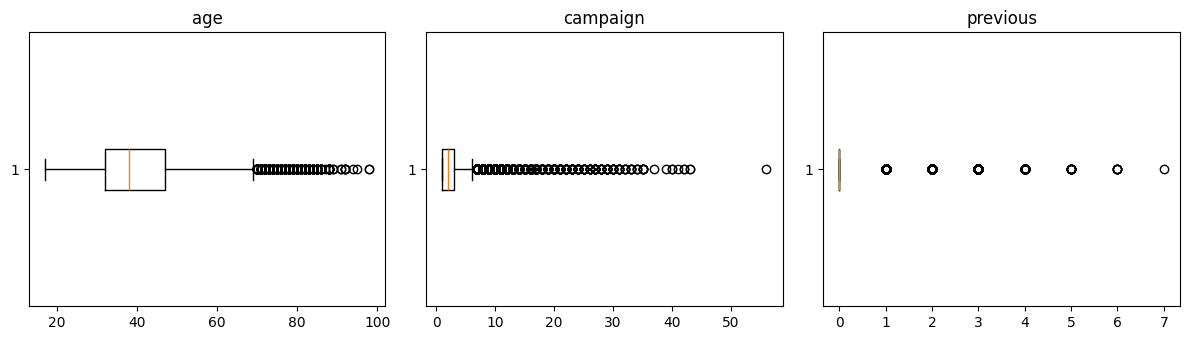

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ['age', 'campaign', 'previous']):
    ax.boxplot(df[col], vert=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [13]:
print(df['age'].describe())
print(df['campaign'].value_counts().sort_index().tail(10))
print(df['previous'].value_counts().sort_index())

count    41176.00000
mean        40.02380
std         10.42068
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64
campaign
33    4
34    3
35    5
37    1
39    1
40    2
41    1
42    2
43    2
56    1
Name: count, dtype: int64
previous
0    35551
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64


Pela regra do IQR, age tem 468 outliers (1,14 %, acima de 69,5 anos), campaign tem 2 406 (5,84 %, acima de 6 contactos, máximo 56) e previous tem 5 625 (13,66 %).

Em age são clientes mais velhos e em campaign são clientes contactados muitas vezes, ambos casos plausíveis, por isso mantive-os (em campaign posso limitar os valores mais altos). 

Em previous, 86,3 % dos clientes têm 0, logo Q1 = Q3 = 0, o IQR é 0 e qualquer valor positivo é marcado como outlier.

B5 - AUC de duration

In [14]:
from sklearn.metrics import roc_auc_score

auc_duration = roc_auc_score(df['y_bin'], df['duration'])
print(f"AUC de duration sozinha: {auc_duration:.3f}")

AUC de duration sozinha: 0.818


In [15]:
df_modelo = df.drop(columns=['duration'])

A AUC de duration é 0,818, o que demonstra ser um valor demasiado alto para uma única variável.

A duração só se conhece depois de a chamada terminar e depende do interesse do cliente (quem quer subscrever fala mais tempo), por isso não está disponível quando a equipa decide a quem ligar. Usá-la seria fuga de informação (data leakage), pelo que se excluíu dos modelos da parte D.

### **Parte C**

---



C1 - Correlação + Heatmap

In [26]:
eco = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

corr = df[eco].corr()
corr.round(2)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.20,0.06,1.00,0.28,0.10
euribor3m,0.97,0.69,0.28,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


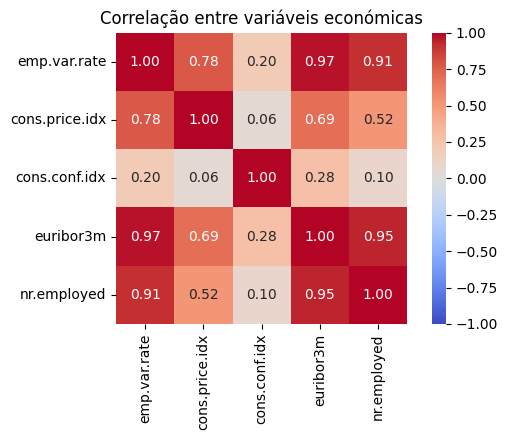

In [27]:
import seaborn as sns

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlação entre variáveis económicas')
plt.tight_layout()
plt.show()

In [28]:
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack()
             .loc[lambda s: s.abs() > 0.8]
             .sort_values(key=abs, ascending=False))
pares

emp.var.rate  euribor3m      0.972244
euribor3m     nr.employed    0.945146
emp.var.rate  nr.employed    0.906949
dtype: float64

In [29]:
df[eco + ['y_bin']].corr()['y_bin'].drop('y_bin').round(3)

emp.var.rate     -0.298
cons.price.idx   -0.136
cons.conf.idx     0.055
euribor3m        -0.308
nr.employed      -0.355
Name: y_bin, dtype: float64

Com |r| > 0,8, três variáveis são redundantes entre si, sendo elas a emp.var.rate, euribor3m e nr.employed (r entre 0,91 e 0,97), porque todas medem o mesmo ciclo económico. cons.price.idx (máx. 0,78) e cons.conf.idx (máx. 0,28) ficam abaixo do limiar. 

Das três redundantes guardaríamos nr.employed, que tem a correlação mais forte com o alvo (r = −0,355).

C2 - PCA

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_eco = StandardScaler().fit_transform(df[eco])
pca = PCA().fit(X_eco)

var = pca.explained_variance_ratio_
acum = var.cumsum()

pd.DataFrame({'componente': [f'PC{i+1}' for i in range(len(var))],
              'variancia_%': (var*100).round(2),
              'acumulada_%': (acum*100).round(2)})

,componente,variancia_%,acumulada_%
0,PC1,69.42,69.42
1,PC2,19.65,89.07
2,PC3,10.21,99.28
3,PC4,0.50,99.79
4,PC5,0.21,100.00


In [31]:
n95 = int(np.argmax(acum >= 0.95) + 1)
print(f"1.ª componente: {var[0]:.1%} | componentes para 95 %: {n95}")

1.ª componente: 69.4% | componentes para 95 %: 3


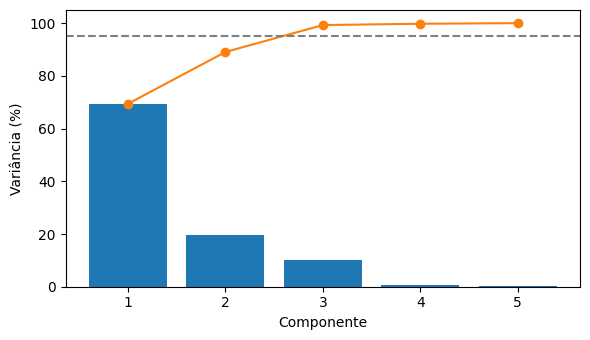

In [32]:
plt.figure(figsize=(6, 3.5))
plt.bar(range(1, 6), var*100)
plt.plot(range(1, 6), acum*100, marker='o', color='C1')
plt.axhline(95, ls='--', color='gray')
plt.xlabel('Componente'); plt.ylabel('Variância (%)')
plt.tight_layout(); plt.show()

Depois de padronizadas, a 1.ª componente explica 69,4 % da variância e são precisas 3 componentes para chegar a 95% (99,3%). Ou seja, as cinco variáveis económicas resumem-se a três dimensões, sendo que uma só já explica quase 70%. 

A redundância é vista no bloco económico, pois tem muito menos informação independente do que as 5 outras colunas sugerem.

### **Parte D**

---



Refaça o gráfico (b) do Exercício 2 em plotly express, com hover a mostrar a espécie e as medidas. Em 2 linhas: em que contextos a interatividade compensa?



In [ ]:
import plotly.express as px

fig = px.scatter(
    d, x='bill_length_mm', y='bill_depth_mm', color='species',
    color_discrete_map=cores,
    hover_name='species',
    hover_data={'bill_length_mm': ':.1f', 'bill_depth_mm': ':.1f',
                'flipper_length_mm': True, 'body_mass_g': True,
                'species': False},
    labels={'bill_length_mm': 'Comprimento do bico (mm)',
            'bill_depth_mm': 'Profundidade do bico (mm)',
            'flipper_length_mm': 'Barbatana (mm)',
            'body_mass_g': 'Massa (g)'},
    title='Por espécie, bicos mais longos são também mais profundos')
fig.show()

A interatividade compensa na exploração de muitos pontos (identificar outliers, ler valores exatos) e em dashboards ou relatórios online, onde o leitor quer ir ao detalhe. Não compensa em papel, slides ou artigos, onde o gráfico tem de se explicar sozinho e as anotações estáticas comunicam melhor.


